# 04 · Ingestión, reintentos y diagnóstico

[Índice MQTT](00_indice_mqtt.ipynb) · [Anterior](03_topics_y_contrato_de_datos.ipynb)

## De la conexión al trabajador

Con `MQTT_CONVERT_RAW=true` (valor predeterminado), `backend/mqtt_ingest.py` gestiona tanto el JSON tratado como la recuperación del CSV. FastAPI abre el pool de PostgreSQL y después arranca el cliente Paho. `connect_async()` y `loop_start()` dejan el socket a cargo de un hilo de red. Cada `on_connect` aceptado solicita las suscripciones otra vez y `on_subscribe` comunica el estado de los filtros. `on_disconnect` notifica que se perdió el enlace.

El callback `on_message` distingue estados de lecturas. Los estados válidos van directamente a la actualización en memoria. Las lecturas válidas en tamaño y estructura de tema se encolan sin bloquear el hilo. La cola de entrada tiene 100 posiciones y el trabajador `mqtt-ingest` la consume. Este trabajador valida, usa PostgreSQL y espera hasta 10 s el PUBACK de sus publicaciones tratadas. Si esa espera ocurriera en el propio hilo MQTT, bloquearía el trabajo necesario para recibir el PUBACK. La comunicación de cambios al bucle HTTP se realiza con `loop.call_soon_threadsafe`. [Hilo de red y confirmaciones en Paho](https://eclipse.dev/paho/files/paho.mqtt.python/html/client.html)

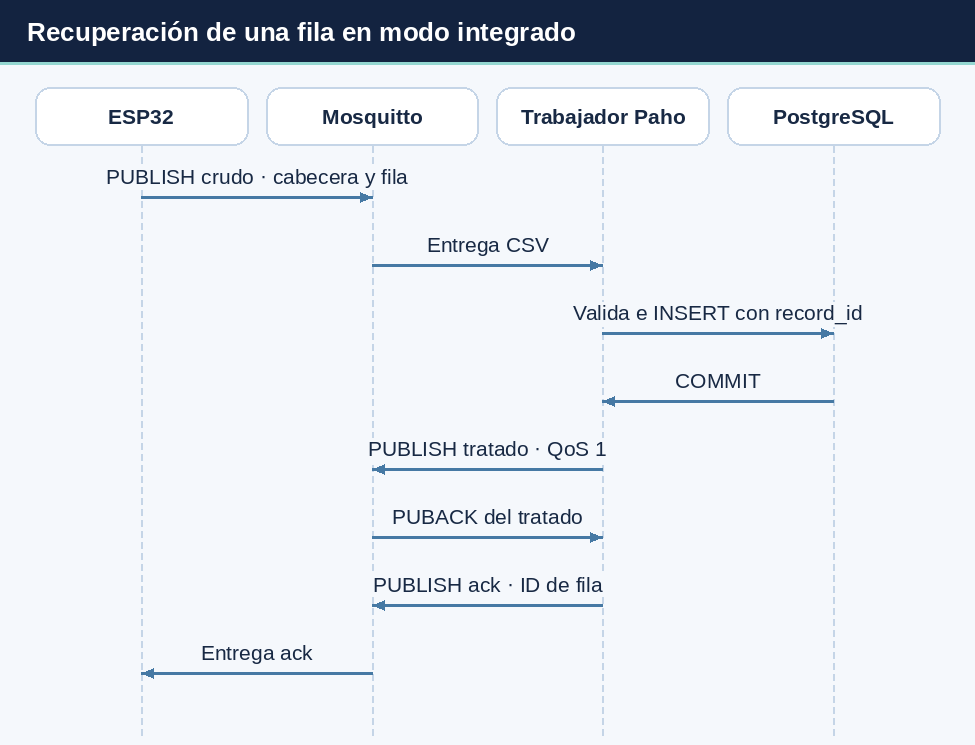

## Avance del archivo y repetición

El lazo del ESP32 busca reconectar cada 5 s y toma una muestra aproximadamente cada 2 s. Si está desconectado o `publish()` indica fallo local, la fila pasa a `/pending.csv` en LittleFS. Tras reconectar, se relee una fila pendiente cada 5 s con el mismo ID hasta recibir su `ack`. La placa guarda en NVS la posición posterior a esa fila y limpia el archivo completo cuando todas se han confirmado. Las nuevas muestras siguen circulando por la ruta normal durante la recuperación.

Un envío QoS 0 aceptado localmente puede perderse entre la placa y el consumidor, por ejemplo si el proceso Python está apagado cuando Mosquitto lo distribuye. La placa guarda la lectura si detecta error de publicación o desconexión, y el histórico alojado en LittleFS permite reintentar las filas que alcanzaron ese archivo. Con la red recuperada, el ritmo máximo de recuperación es aproximadamente 12 filas por minuto. Una interrupción de diez minutos puede producir unas 300 filas y requerir cerca de 25 minutos de recuperación sin fallos ni pausas adicionales.

| Momento del fallo | Efecto sobre la fila pendiente |
| --- | --- |
| Paho descarta por cola llena o validación | La placa queda a la espera y vuelve a enviar. Un CSV mal formado requiere corregir la causa de que el pendiente se rechace. |
| Falla la transacción de PostgreSQL | La transacción revierte y no se ejecuta la publicación de confirmación. |
| Hay COMMIT y se pierde el PUBACK de `tratado` | La fila ya existe; Python espera una nueva recepción del CSV para volver a confirmar. |
| Sale `ack` de Python y la placa pierde el mensaje antes de guardarlo | El siguiente intento usa el mismo ID; Python puede volver a enviar el ACK. |
| NVS guarda el offset | El siguiente intento empieza con la fila posterior; el archivo se conserva hasta terminar. |

El éxito al pedir la publicación de `ack` en Paho no prueba que el ESP32 ya avanzó. El cliente de red también puede reenviar publicaciones QoS 1 según el estado de la conexión. Por eso la seguridad de eliminación depende de `onMqttMessage()` en la placa y la seguridad sobre duplicados depende del almacenamiento.

## Idempotencia y diferencias entre modos

**Idempotencia** significa que repetir la misma operación deja el mismo efecto que aplicarla una vez. Al insertar una lectura de recuperación, PostgreSQL impone `UNIQUE (device_id, record_id)`; el INSERT usa `ON CONFLICT (device_id, record_id) DO NOTHING`. Un duplicado puede venir del reintento del ESP32 o de la suscripción del propio backend al `tratado` que emitió al recuperar el CSV. En ambos casos se conserva una sola fila. La lectura directa carece de `record_id`, y PostgreSQL permite múltiples filas con NULL en esa columna.

| Modo | Suscripción a `crudo` | Antes de emitir `ack` | Identificador en el JSON de salida |
| --- | --- | --- | --- |
| Integrado, `MQTT_CONVERT_RAW=true` | Backend | Valida, confirma la transacción y recibe PUBACK de `tratado`. | Sí. |
| Puente independiente, `MQTT_CONVERT_RAW=false` en el backend | Proceso `backend.scripts.csv_to_json` | Convierte y recibe PUBACK de `tratado`. La persistencia del JSON por el backend ocurre aparte. | El puente conserva el ID para `ack`; su payload JSON carece de este campo. |

En modo independiente, `CsvMqttBridge` arranca un trabajador que convierte mensajes y el proceso principal ejecuta `loop_forever()`. Para usarlo junto al backend, deja `MQTT_CONVERT_RAW=false` en la configuración activa del backend y reinícialo antes de arrancar el puente. Dos consumidores simultáneos de `crudo` pueden producir publicaciones duplicadas para una sola fila original.

## Prueba del puente con Mosquitto aislado

Usa el broker de loopback del [laboratorio de Mosquitto](02_broker_mosquitto_y_red.ipynb). Esta prueba ejecuta **solo** el puente independiente contra ese broker, sin PostgreSQL y sin placa. Desde la raíz `ESP32`, en una terminal separada, confirma que el entorno Python tiene las dependencias declaradas en `backend/scripts/requirements.txt`.

```bash
backend/.venv/bin/python -m backend.scripts.csv_to_json \
  --host 127.0.0.1 --port 18883
```

Espera a que el puente anuncie su conexión de MQTT. En otra terminal suscríbete a los resultados, con tiempo suficiente para enviar la prueba desde una tercera.

```bash
mosquitto_sub -h 127.0.0.1 -p 18883 -V mqttv311 -q 1 -v -C 2 -W 30 \
  -t 'dispositivo/DEMO_LOCAL/tratado' \
  -t 'dispositivo/DEMO_LOCAL/ack'
```

Publica una cabecera y una fila en un **solo** mensaje. `-s` lee la entrada estándar completa; `-l` separaría el envío por líneas, lo que incumpliría este contrato.

```bash
mosquitto_pub -h 127.0.0.1 -p 18883 -V mqttv311 -q 0 \
  -t 'dispositivo/DEMO_LOCAL/crudo' -s <<'CSV'
id,device_id,timestamp,temperature,humidity,gas,calibrate
demo-001,DEMO_LOCAL,2026-11-20T14:30:00-06:00,25.00,67.50,,false
CSV
```

El observador debe mostrar un JSON con `device_id` igual a `DEMO_LOCAL` y `measurements.gas.value` igual a `null`, seguido por un ACK con payload `demo-001`. Si repites la suscripción y el envío conservando el ID, el puente independiente puede volver a emitir ambos mensajes. Se observa la diferencia entre reconfirmar y deduplicar al guardar. Para una variante, cambia el ID de placa dentro del CSV y deja igual el tema: el puente registra el rechazo y el observador expira sin ACK. [Manual de mosquitto_pub y entrada estándar](https://mosquitto.org/man/mosquitto_pub-1.html)

## Diagnóstico guiado al usar la placa o el backend

| Síntoma | Evidencia que debes buscar | Dónde revisar |
| --- | --- | --- |
| Ni estado ni lecturas | Accesibilidad de IP/puerto, CONNACK y SUBACK en Mosquitto | Broker, Wi-Fi, Client ID y alcance de red. |
| Hay estado retenido, ninguna lectura directa | Observación de `tratado` durante varios intervalos de 2 s | Ciclo del firmware, publicación y conexión actual. Un retenido puede ser anterior a tu prueba. |
| Hay `crudo` repetido, sin `ack` | Cabecera exacta, ID, errores de conversión, de PostgreSQL o de tiempo de PUBACK | Logs del consumidor y modo `MQTT_CONVERT_RAW`. |
| `ack` visible, misma fila en la placa | Coincidencia del ID, suscripción de la placa y guardado de su offset | Tema exacto de ACK, red del ESP32 y NVS. |
| Llega JSON, ninguna fila | Hora con desplazamiento, booleano `calibrate`, números finitos y estado de PostgreSQL | `parse_reading()` y logs del backend. |
| Hay histórico, gráfica vacía | El valor de `measured_at` y el intervalo elegido | Sincronización NTP y filtros temporales. |
| Desconexiones inmediatamente tras conectar | Logs del broker para el mismo Client ID | Cada placa y consumidor deben tener un ID único. |

En una base de pruebas del modo integrado puedes verificar la cantidad de veces que se guardó un determinado registro con una consulta de solo lectura. Suponiendo que enviaste la misma fila de laboratorio dos veces con el modo integrado activo, el recuento esperado es `1`.

```sql
SELECT count(*)
FROM readings
WHERE device_id = 'DEMO_LOCAL' AND record_id = 'demo-001';
```

El ACK visible acredita que se emitió un resultado MQTT; el recuento confirma el efecto en PostgreSQL. La posición NVS completa la tercera verificación en una placa física.

[Índice MQTT](00_indice_mqtt.ipynb) · [Anterior](03_topics_y_contrato_de_datos.ipynb)